In [1]:
#셀 1: 라이브러리와 경로 설정

import pandas as pd                          # 표(데이터프레임) 처리 라이브러리
import numpy as np                           # 숫자 계산 라이브러리
from pathlib import Path                     # 폴더·파일 경로를 다루는 도구

BASE = Path(".") if (Path(".") / "시뮬레이션 사용 데이터").is_dir() else Path("..")  # 저장소 루트 또는 simulation 폴더에서 실행
BERTH_DIR = BASE / "시뮬레이션 사용 데이터" / "berth"          # 터미널별 선석배정 파일 폴더
CONTAINER_DIR = BASE / "시뮬레이션 사용 데이터" / "container"  # 컨테이너 반입·반출 파일 폴더
PORTMIS_DIR = BASE / "시뮬레이션 사용 데이터" / "portmis"      # 포트미스 입출항 파일 폴더
VESSEL_DIR = BASE / "시뮬레이션 사용 데이터" / "vessel"        # 선박 제원 파일 폴더
OUT_DIR = BASE / "output"                    # 결과를 저장할 폴더
OUT_DIR.mkdir(exist_ok=True)                 # output 폴더가 없으면 만든다

YEAR = 2025                                  # 분석할 연도

pd.set_option("display.width", 200)          # 표를 출력할 때 한 줄 너비를 넓힌다
pd.set_option("display.max_columns", 50)     # 열이 생략되지 않게 표시할 최대 열 수를 늘린다

for folder in [BERTH_DIR, CONTAINER_DIR, PORTMIS_DIR, VESSEL_DIR]:
    print(folder, "->", sorted(p.name for p in folder.iterdir()))

data\berth -> ['BCT_2025_선석배정현황.xlsx', 'BNCT_2025_선석배정현황.xlsx', 'DGT_2025_선석배정현황.xlsx', 'HJNC_2025_선석배정현황.xlsx', 'HPNT_2025_선석배정현황.xls', 'PNC_선석배정현황_2025.xlsx', 'PNIT_2025_선석배정현황.xls']
data\container -> ['DGT_DGT.csv', 'DGT_HJNC_2025.csv', 'hjnc_hjnc.csv']
data\portmis -> ['portmis_2025.csv']
data\vessel -> ['vessel_spec_미확인.csv', 'vessel_spec_선박크기.csv']


In [2]:
# 셀 2: HJNC 선석배정 파일 읽기
hjnc_file = [p for p in BERTH_DIR.glob("*.xls*")      # berth 폴더의 엑셀 파일 중에서
             if "HJNC" in p.name.upper()]             # 이름에 HJNC가 들어간 파일을 찾는다
print(hjnc_file)                                      # 정확히 1개가 나와야 한다

hjnc_raw = pd.read_excel(hjnc_file[0], header=1)
print(hjnc_raw.shape)
print(hjnc_raw.columns.tolist())
hjnc_raw.head()

[WindowsPath('data/berth/HJNC_2025_선석배정현황.xlsx')]


C:\Users\user\Desktop\busan_sim\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


(1002, 18)
['No', '선석', '항로', '모선항차', '선박명', '선사항차', '접안', '선사', '반입 시작일시', '반입 마감일시', '입항일시', '출항일시', '작업 시작일시', '작업 완료일시', '양하', '선적', 'S/H', '전배']


,No,선석,항로,모선항차,선박명,선사항차,접안,선사,반입 시작일시,반입 마감일시,입항일시,출항일시,작업 시작일시,작업 완료일시,양하,선적,S/H,전배
0,1,1B,MD3,YWDM-2024-0002,YM WISDOM,020W-021W,S,YML,2024-12-28 00:00,2024-12-31 06:00,2024-12-31 15:54,2025-01-02 23:00,2024-12-31 17:30,2025-01-02 21:46,3122,1276,2166,NaN
1,2,1B,SIS2,ZGHZ-2025-0001,ZHONG GU HANG ZHOU,24005W-24005W,S,TSL,2024-12-31 00:00,2025-01-02 15:00,2025-01-03 00:55,2025-01-03 22:00,2025-01-03 14:10,2025-01-03 21:42,807,514,24,NaN
2,3,1B,JVH,OSWR-2025-0001,SWAN RIVER BRIDGE,105S-105S,S,ONE,2025-01-01 00:00,2025-01-03 14:00,2025-01-04 00:05,2025-01-04 11:00,2025-01-04 00:53,2025-01-04 10:59,252,444,6,NaN
3,4,1B,AIS,KKJA-2025-0001,KMTC JEBEL ALI,2409W-2409W,P,KMD,2025-01-01 00:00,2025-01-04 03:00,2025-01-04 13:50,2025-01-05 03:00,2025-01-04 14:50,2025-01-05 02:23,570,503,0,NaN
4,5,1B,PN3E,HOPD-2025-0001,HMM PERIDOT,004E-004E,S,HMM,2025-01-02 00:00,2025-01-04 19:00,2025-01-05 06:05,2025-01-07 05:01,2025-01-05 07:04,2025-01-07 03:40,1443,2737,12,NaN


In [3]:
# 셀 3: 변환 도구 함수
def num(s):
    """쉼표·공백·'-'가 섞인 열을 숫자로 바꾼다. 바꿀 수 없는 값은 빈 값(NaN)이 된다."""
    cleaned = (s.astype(str)                          # 우선 모두 문자열로 바꾸고
                .str.replace(",", "")                 # 천 단위 쉼표를 없애고
                .str.strip()                          # 앞뒤 공백을 지우고
                .replace({"null": None, "-": None, "nan": None}))   # 값이 없다는 뜻의 글자는 빈 값으로
    return pd.to_numeric(cleaned, errors="coerce")    # 숫자로 변환 (실패하면 NaN)


def dt(s):
    """문자열 열을 날짜·시각으로 바꾼다. 바꿀 수 없는 값은 빈 값(NaT)이 된다."""
    return pd.to_datetime(s.replace({"-": None, "null": None}), errors="coerce")

In [4]:
# 셀 4: HJNC를 공통 형식으로 변환
def load_hjnc(raw):
    """HJNC 원본 표를 공통 열 이름의 표로 바꾼다."""
    return pd.DataFrame({
        "terminal": "HJNC",                           # 터미널 이름 (모든 행에 같은 값)
        "berth": raw["선석"].astype(str),              # 선석 번호
        "vessel": raw["선박명"],                       # 선박 이름
        "voyage": raw["모선항차"],                     # 모선 항차
        "carrier": raw["선사"],                        # 선사
        "route": raw["항로"],                          # 항로
        "gate_open": dt(raw["반입 시작일시"]),         # 컨테이너 반입 시작(게이트 오픈) 시각
        "gate_cutoff": dt(raw["반입 마감일시"]),       # 반입 마감 시각
        "etb": dt(raw["입항일시"]),                    # 접안 시각 (HJNC는 '입항일시' 열이 접안 시각)
        "etd": dt(raw["출항일시"]),                    # 출항 시각
        "work_start": dt(raw["작업 시작일시"]),        # 하역 작업 시작
        "work_end": dt(raw["작업 완료일시"]),          # 하역 작업 완료
        "discharge": num(raw["양하"]),                 # 양하(내리는) 수량
        "load": num(raw["선적"]),                      # 적하(싣는) 수량
        "shift": num(raw["S/H"]),                      # 선내 이동(shift) 수량
        "status": None,                               # HJNC에는 상태 열이 없다
    })

hjnc = load_hjnc(hjnc_raw)                            # 변환 실행
print(hjnc.shape)                                     # 행 수 확인
print(hjnc.dtypes)                                    # 각 열이 날짜·숫자로 잘 바뀌었는지 확인
print(hjnc[["etb", "etd"]].isna().sum())              # 접안·출항 시각이 비어 있는 행 수 (0에 가까워야 한다)
print(hjnc["etb"].min(), "~", hjnc["etb"].max())      # 접안 시각의 범위 (2025년이어야 한다)
hjnc.head()

(1002, 16)
terminal                  str
berth                     str
vessel                    str
voyage                    str
carrier                   str
route                     str
gate_open      datetime64[us]
gate_cutoff    datetime64[us]
etb            datetime64[us]
etd            datetime64[us]
work_start     datetime64[us]
work_end       datetime64[us]
discharge               int64
load                    int64
shift                   int64
status                 object
dtype: object
etb    0
etd    0
dtype: int64
2024-12-30 22:30:00 ~ 2025-12-31 08:40:00


,terminal,berth,vessel,voyage,carrier,route,gate_open,gate_cutoff,etb,etd,work_start,work_end,discharge,load,shift,status
0,HJNC,1B,YM WISDOM,YWDM-2024-0002,YML,MD3,2024-12-28,2024-12-31 06:00:00,2024-12-31 15:54:00,2025-01-02 23:00:00,2024-12-31 17:30:00,2025-01-02 21:46:00,3122,1276,2166,None
1,HJNC,1B,ZHONG GU HANG ZHOU,ZGHZ-2025-0001,TSL,SIS2,2024-12-31,2025-01-02 15:00:00,2025-01-03 00:55:00,2025-01-03 22:00:00,2025-01-03 14:10:00,2025-01-03 21:42:00,807,514,24,None
2,HJNC,1B,SWAN RIVER BRIDGE,OSWR-2025-0001,ONE,JVH,2025-01-01,2025-01-03 14:00:00,2025-01-04 00:05:00,2025-01-04 11:00:00,2025-01-04 00:53:00,2025-01-04 10:59:00,252,444,6,None
3,HJNC,1B,KMTC JEBEL ALI,KKJA-2025-0001,KMD,AIS,2025-01-01,2025-01-04 03:00:00,2025-01-04 13:50:00,2025-01-05 03:00:00,2025-01-04 14:50:00,2025-01-05 02:23:00,570,503,0,None
4,HJNC,1B,HMM PERIDOT,HOPD-2025-0001,HMM,PN3E,2025-01-02,2025-01-04 19:00:00,2025-01-05 06:05:00,2025-01-07 05:01:00,2025-01-05 07:04:00,2025-01-07 03:40:00,1443,2737,12,None


In [5]:
# 셀 5: HPNT, PNIT (HTML 형식의 .xls)
import io                                             # 문자열을 파일처럼 다루는 도구

def find_one(keyword):
    """berth 폴더에서 이름에 keyword가 들어간 파일을 정확히 하나 찾는다."""
    hits = [p for p in BERTH_DIR.glob("*.xls*") if keyword.upper() in p.name.upper()]
    assert len(hits) == 1, f"{keyword} 파일이 {len(hits)}개: {hits}"   # 0개나 2개 이상이면 멈춘다
    return hits[0]

def read_html_table(path):
    """확장자는 .xls지만 내용은 HTML 표인 파일에서 가장 큰 표를 읽는다."""
    text = open(path, encoding="utf-8").read()        # 파일을 글자로 읽는다
    tables = pd.read_html(io.StringIO(text), flavor="lxml")   # HTML 안의 표를 모두 찾아서
    return max(tables, key=len)                       # 행이 가장 많은 표를 고른다

hpnt_raw = read_html_table(find_one("HPNT"))          # HPNT 원본
pnit_raw = read_html_table(find_one("PNIT"))          # PNIT 원본
print("HPNT", hpnt_raw.shape, hpnt_raw.columns.tolist())   # 크기와 열 이름 확인
print("PNIT", pnit_raw.shape, pnit_raw.columns.tolist())


def load_hpnt(raw):
    return pd.DataFrame({
        "terminal": "HPNT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": dt(raw["반입시작일시"]), "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),   # 접안·출항 시각
        "work_start": pd.NaT, "work_end": pd.NaT,     # HPNT에는 작업 시각 열이 없다
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

def load_pnit(raw):
    return pd.DataFrame({
        "terminal": "PNIT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT,                          # PNIT에는 반입 시작 열이 없다
        "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

hpnt = load_hpnt(hpnt_raw)
pnit = load_pnit(pnit_raw)
for name, t in [("HPNT", hpnt), ("PNIT", pnit)]:     # 두 터미널을 같은 방식으로 점검
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())

HPNT (887, 15) ['선석', '선사', '모선항차', '선사항차', '선명', 'ROUTE', '반입시작일시', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
PNIT (699, 15) ['선석', '선사', '모선항차', '선사항차', 'Head (Bridge) Stern', '선명', 'ROUTE', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
HPNT (887, 16) 접안 결측 0 | 2024-12-31 07:06:00 ~ 2025-12-31 23:36:00
PNIT (699, 16) 접안 결측 0 | 2024-12-30 01:35:00 ~ 2025-12-31 12:30:00


In [6]:
# 셀 6: BCT, BNCT
bct_raw = pd.read_excel(find_one("BCT"))              # BCT 원본 (BNCT 파일 이름에도 'CT'가 있지만 'BCT'는 겹치지 않는다)
bnct_raw = pd.read_excel(find_one("BNCT"))            # BNCT 원본
print("BCT", bct_raw.shape, bct_raw.columns.tolist())
print("BNCT", bnct_raw.shape, bnct_raw.columns.tolist())


def load_bct(raw):
    return pd.DataFrame({
        "terminal": "BCT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선/항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["CCT"]),     # CCT = 반입 마감 시각
        "etb": dt(raw["접안예정시간(ETB)"]), "etd": dt(raw["출항예정시간(ETD)"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["이적"]),
        "status": raw["상태"]})

def load_bnct(raw):
    c = list(raw.columns)                             # BNCT는 열 이름이 길어서 위치(순서)로 읽는다
    wl = raw[c[7]].astype(str).str.split("/", expand=True)   # '양하/적하/이적'으로 합쳐진 열을 나눈다
    return pd.DataFrame({
        "terminal": "BNCT", "berth": raw[c[0]].astype(str),
        "vessel": raw[c[3]].astype(str).str.replace(r"\(.*\)$", "", regex=True).str.strip(),  # 선박명 뒤 (항로) 제거
        "voyage": raw[c[2]].astype(str).str.extract(r"^(\S+)")[0],
        "carrier": raw[c[1]],
        "route": raw[c[3]].astype(str).str.extract(r"\(([^()]*)\)$")[0],     # 괄호 안 글자를 항로로
        "gate_open": pd.NaT, "gate_cutoff": dt(raw[c[4]]),
        "etb": dt(raw[c[5]]), "etd": dt(raw[c[6]]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw[c[8]]})

bct = load_bct(bct_raw)
bnct = load_bnct(bnct_raw)
for name, t in [("BCT", bct), ("BNCT", bnct)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
bnct.head()                                           # BNCT는 열 분리가 맞는지 눈으로 확인

C:\Users\user\Desktop\busan_sim\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


BCT (1044, 18) ['No', '선석', '선사', '모선/항차', '입항', '출항', 'CCT', '접안예정시간(ETB)', '출항예정시간(ETD)', '양하', '적하', '이적', '모선명', 'ROUTE', '전배TML', '검역', '줄잡이업체', '상태']
BNCT (987, 9) ['선석', '선사', '모선항차(선사항차)\nHead (Bridge) Stern', '선명\n(ROUTE)', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '작업량\n양하 / 적하 / Shift', '상태']
BCT (1044, 16) 접안 결측 0 | 2024-12-31 20:00:00 ~ 2025-12-30 18:00:00
BNCT (987, 16) 접안 결측 0 | 2024-12-30 14:24:00 ~ 2025-12-31 23:24:00


,terminal,berth,vessel,voyage,carrier,route,gate_open,gate_cutoff,etb,etd,work_start,work_end,discharge,load,shift,status
0,BNCT,1(S),PRESIDENT BUSH,APBU001,APL,EX1E,NaT,2024-12-30 19:41:00,2024-12-31 08:35:00,2025-01-01 05:55:00,NaT,NaT,259,911,12,DEPARTED
1,BNCT,4(P),CMA CGM ALMAVIVA,CMAV005,CMA,PE3OA,NaT,2024-12-30 17:00:00,2024-12-31 04:18:00,2025-01-01 07:00:00,NaT,NaT,850,1351,0,DEPARTED
2,BNCT,3(S),ALS LUNA,CALU006,CMA,ACSAE,NaT,2024-12-29 11:13:00,2024-12-30 14:24:00,2025-01-01 08:05:00,NaT,NaT,900,949,6,DEPARTED
3,BNCT,4(S),PRESIDENT REAGAN,APRE001,APL,EX1W,NaT,2024-12-31 23:00:00,2025-01-01 09:35:00,2025-01-02 11:46:00,NaT,NaT,796,709,84,DEPARTED
4,BNCT,1(S),CMA CGM NIAGARA,CANR004,CMA,PHXOA,NaT,2024-12-31 22:00:00,2025-01-01 08:30:00,2025-01-02 18:00:00,NaT,NaT,1235,1272,232,DEPARTED


In [7]:
 # 셀 7: PNC, DGT (시트 이름으로 읽기)
pnc_raw = pd.read_excel(find_one("PNC"), sheet_name="2025 선석배정현황")   # PNC: 여러 시트 중 선석배정 시트만 읽는다
dgt_raw = pd.read_excel(find_one("DGT"), sheet_name="2025 선석배정현황")   # DGT: 같은 이름의 시트
print("PNC", pnc_raw.shape, pnc_raw.columns.tolist())
print("DGT", dgt_raw.shape, dgt_raw.columns.tolist())


def load_pnc(raw):
    return pd.DataFrame({
        "terminal": "PNC", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선코드"],
        "carrier": raw["운항선사"], "route": raw["항로"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["반입마감일시"]),      # PNC는 반입 시작 열이 없다
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하수량"]), "load": num(raw["선적수량"]), "shift": num(raw["Shift"]),
        "status": None})

def load_dgt(raw):
    c = list(raw.columns)                             # DGT는 일부 열을 위치로 읽는다
    wl = raw[c[12]].astype(str).str.split("/", expand=True)   # 13번째 열: '양하/적하/이적'이 합쳐져 있다
    return pd.DataFrame({
        "terminal": "DGT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw[c[2]],
        "carrier": raw["선사코드"], "route": raw["항로"],
        "gate_open": dt(raw["반입시작시간"]), "gate_cutoff": dt(raw["반입마감시간"]),
        "etb": dt(raw["접안예정일시"]), "etd": dt(raw["출항예정일시"]),
        "work_start": dt(raw["작업시작시간"]), "work_end": dt(raw["작업완료시간"]),
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw["상태"]})

pnc = load_pnc(pnc_raw)
dgt = load_dgt(dgt_raw)
for name, t in [("PNC", pnc), ("DGT", dgt)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
dgt.head()                                            # DGT는 양하/적하 분리가 맞는지 확인

PNC (1385, 17) ['No.', '모선명', '모선코드', '선사항차', '운항선사', '항로', '접안방향', '접안(예정)일시', '출항(예정)일시', '선석', '반입마감일시', '양하수량', '선적수량', 'Shift', '줄잡이업체', '작업서류', '업데이트일시']
DGT (1050, 14) ['선석', '선사코드', '모선항차(선사항차)', '모선명', '항로', '반입시작시간', '반입마감시간', '접안예정일시', '출항예정일시', '작업시작시간', '작업완료시간', 'Head (Bridge) Stern', '작업량\n양하/적하/Shift', '상태']
PNC (1385, 16) 접안 결측 0 | 2025-01-01 04:00:00 ~ 2025-12-31 20:00:00
DGT (1050, 16) 접안 결측 0 | 2025-01-01 02:00:00 ~ 2025-12-31 14:00:00


,terminal,berth,vessel,voyage,carrier,route,gate_open,gate_cutoff,etb,etd,work_start,work_end,discharge,load,shift,status
0,DGT,B2(P),PORT VILA CHIEF,SWPV-004/2024 (2410N/2501S),SWI,SWL,2024-12-28,2024-12-31 14:00:00,2025-01-01 02:00:00,2025-01-01 19:00:00,NaT,NaT,NaN,NaN,0,Departed
1,DGT,B1(P),REN JIAN 20,SCRJ-003/2024 (2409E/2409E),SML,HJNC,2024-12-28,2024-12-31 20:00:00,2025-01-01 08:00:00,2025-01-02 06:00:00,NaT,NaT,NaN,NaN,0,Departed
2,DGT,B3(P),EVER CHASTE,CHAS-014/2024 (0078-066N/0081-067S),EMC,KTH,2024-12-28,2025-01-01 05:00:00,2025-01-01 17:00:00,2025-01-02 09:00:00,NaT,NaT,NaN,NaN,0,Departed
3,DGT,B2(P),WAN HAI 503,W503-001/2025 (E215/W216),WHL,CI5,2024-12-28,2025-01-01 11:00:00,2025-01-01 23:00:00,2025-01-02 15:00:00,NaT,NaT,NaN,NaN,0,Departed
4,DGT,B1(P),XIN LONG YUN 16,XL16-001/2025 (SHA09S/SHA09N),DLK,GBS,2024-12-30,2025-01-01 20:00:00,2025-01-02 08:00:00,2025-01-02 12:00:00,NaT,NaT,NaN,NaN,0,Departed


In [8]:
# 셀 8: 7개 터미널 합치기와 2025년 필터
berth_all = pd.concat([hjnc, hpnt, pnit, bct, bnct, pnc, dgt], ignore_index=True)   # 7개 표를 위아래로 이어 붙인다
print("합친 행 수:", len(berth_all))

berth_all = berth_all.dropna(subset=["etb", "etd"])   # 접안·출항 시각이 없으면 시뮬레이션에 쓸 수 없어 제외
berth_all = berth_all[berth_all["etb"].dt.year == YEAR].copy()   # 2025년 접안 건만 남긴다
berth_all = berth_all.reset_index(drop=True)          # 행 번호를 0부터 다시 매긴다
print("정리 후 행 수:", len(berth_all))               # 이전 분석에서는 약 7,042건이었다

summary = berth_all.groupby("terminal").agg(          # 터미널별 요약
    호출수=("vessel", "size"),
    첫접안=("etb", "min"), 마지막접안=("etb", "max"),
    평균점유h=("etd", lambda s: 0))                     # 자리표시 (아래에서 계산)
summary["평균점유h"] = (berth_all["etd"] - berth_all["etb"]).dt.total_seconds().div(3600).groupby(berth_all["terminal"]).mean().round(1)
print(summary)

print("\n열별 결측률(%)")
cols = ["gate_open", "gate_cutoff", "etb", "etd", "work_start", "work_end", "discharge", "load"]
print((berth_all[cols].isna().groupby(berth_all["terminal"]).mean() * 100).round(0))

berth_all.to_csv(OUT_DIR / "berth_2025.csv", index=False, encoding="utf-8-sig")   # 결과 저장 (한글 깨짐 방지 인코딩)

합친 행 수: 7054
정리 후 행 수: 7042
           호출수                 첫접안               마지막접안  평균점유h
terminal                                                     
BCT       1043 2025-01-01 02:00:00 2025-12-30 18:00:00   18.6
BNCT       984 2025-01-01 08:30:00 2025-12-31 23:24:00   21.8
DGT       1050 2025-01-01 02:00:00 2025-12-31 14:00:00   16.4
HJNC       999 2025-01-02 09:10:00 2025-12-31 08:40:00   20.8
HPNT       885 2025-01-01 09:00:00 2025-12-31 23:36:00   21.7
PNC       1385 2025-01-01 04:00:00 2025-12-31 20:00:00   28.7
PNIT       696 2025-01-01 03:40:00 2025-12-31 12:30:00   32.7

열별 결측률(%)
          gate_open  gate_cutoff  etb  etd  work_start  work_end  discharge  load
terminal                                                                         
BCT           100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
BNCT          100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
DGT             0.0          0.0  0.0  0.0        69.0      69.0       69.0

In [9]:
# 셀 9: 선박 제원 읽기
spec_raw = pd.read_csv(VESSEL_DIR / "vessel_spec_선박크기.csv", encoding="utf-8-sig")   # 선박 제원 csv
print(spec_raw.shape)                                 # 1,577행이어야 한다
print(spec_raw.columns.tolist())                      # 열 이름 확인

def name_key(s):
    """선박명 비교용 키: 대문자로 바꾸고 영문자·숫자만 남긴다 (공백·기호 차이를 없앤다)."""
    return s.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)

spec = pd.DataFrame({
    "key": name_key(spec_raw["선박명(엑셀 기재)"]),     # 연결에 쓸 선박명 키
    "LOA": spec_raw["길이 LOA(m)"],                    # 선박 길이(m)
    "beam": spec_raw["폭(m)"],                         # 선박 폭(m)
    "GT": spec_raw["GT"],                              # 총톤수
    "DWT": spec_raw["DWT"],                            # 재화중량톤수
})
print("길이가 있는 선박:", spec["LOA"].notna().sum(), "/", len(spec))   # 1,521 / 1,577 이어야 한다

dup = spec["key"].duplicated(keep=False)              # 키가 같은 선박이 여러 개인지
print("키가 겹치는 행:", dup.sum())                     # 겹치면 연결할 때 행이 늘어날 수 있다
spec = spec.dropna(subset=["LOA"]).drop_duplicates("key")   # 길이가 있는 것만, 같은 키는 하나만 남긴다
print("사용할 제원:", len(spec))
spec.describe()                                       # 길이·폭 분포 확인 (비정상 값 점검)

(1577, 13)
['선박명(엑셀 기재)', '출현 터미널', '선종(VesselFinder)', '건조연도', 'GT', 'DWT', '길이 LOA(m)', '폭(m)', 'VesselFinder 검색명', '비고', 'IMO', '검증상태', '출처']
길이가 있는 선박: 1521 / 1577
키가 겹치는 행: 0
사용할 제원: 1521


,LOA,beam,GT,DWT
count,1521.000000,1521.000000,1519.000000,1521.000000
mean,296.325943,41.961019,91366.874259,104033.883235
std,71.760917,9.513432,53867.236699,58707.129862
min,89.000000,15.000000,3203.000000,4759.000000
25%,260.000000,32.200000,47552.500000,57627.000000
50%,304.000000,43.000000,91023.000000,103518.000000
75%,364.000000,48.000000,140096.000000,142411.000000
max,400.000000,62.000000,236184.000000,281456.000000


In [10]:
# 셀 10: 선석배정 표에 길이 붙이기
berth = berth_all.copy()                              # 원본은 그대로 두고 복사본에 붙인다
berth["key"] = name_key(berth["vessel"])              # 선석배정 표에도 같은 방식으로 키를 만든다

n_before = len(berth)                                 # 연결 전 행 수
berth = berth.merge(spec, on="key", how="left")       # 키로 연결 (제원에 없으면 길이는 빈 값)
assert len(berth) == n_before, "연결하면서 행이 늘었습니다 (키 중복 확인)"   # 행 수가 변하면 멈춘다
berth = berth.drop(columns="key")

g = berth.groupby("terminal")["LOA"]                  # 터미널별 길이 통계
print(pd.DataFrame({
    "호출": g.size(),
    "길이 매칭률(%)": (g.count() / g.size() * 100).round(1),
    "중앙값(m)": g.median().round(0),
    "95%(m)": g.quantile(.95).round(0),
    "최대(m)": g.max().round(0),
}))
print("\n길이가 없는 호출:", berth["LOA"].isna().sum(), "건")
print(berth.loc[berth["LOA"].isna(), "vessel"].value_counts().head(10))   # 길이를 못 붙인 선박 상위 10개

berth.to_csv(OUT_DIR / "berth_2025_loa.csv", index=False, encoding="utf-8-sig")   # 결과 저장

            호출  길이 매칭률(%)  중앙값(m)  95%(m)  최대(m)
terminal                                        
BCT       1043       96.5   148.0   366.0  400.0
BNCT       984       95.7   300.0   366.0  399.0
DGT       1050       89.8   180.0   334.0  369.0
HJNC       999       99.3   272.0   368.0  400.0
HPNT       885       98.6   272.0   366.0  400.0
PNC       1385       94.1   300.0   400.0  400.0
PNIT       696       98.1   330.0   366.0  399.0

길이가 없는 호출: 300 건
vessel
DREDGING                 40
SONG YUN HE              30
HE LE                    22
ZHONG ZHOU CHANG HONG    18
ANDONG 68                18
GLOBAL NUBIRA            11
PACIFIC CARRIER          11
HT HONOROR                9
VANTAGE                   8
VLADIVOSTOK               7
Name: count, dtype: int64


In [11]:
# 셀 11: 터미널 시설과 시뮬레이션 규칙

TERMINALS = {                                         # 터미널별 선석 수와 안벽 길이(m), 부산항만공사 기준
    "PNIT": {"berths": 3, "quay_m": 1200},
    "PNC":  {"berths": 5, "quay_m": 2000},
    "HJNC": {"berths": 4, "quay_m": 1100},
    "HPNT": {"berths": 3, "quay_m": 1150},
    "BNCT": {"berths": 4, "quay_m": 1400},
    "BCT":  {"berths": 3, "quay_m": 1050},
    "DGT":  {"berths": 3, "quay_m": 1050},            # DGT는 1,050m로 확정
}

LOA_MARGIN = 1.0      # 선박이 안벽에서 차지하는 길이 = 선박 길이 × 이 값 (1.0은 실제 관측 대기와 가장 잘 맞았던 설정)
CHANGEOVER_H = 0.0    # 앞 배가 나간 뒤 다음 배가 접안하기까지 간격(시간)
MC_REPS = 10          # 길이를 모르는 선박의 길이를 무작위로 채워 반복하는 횟수
SEED = 20250101       # 난수 시드 (같은 결과가 재현되도록 고정)

SCENARIOS = {         # 시나리오: 같은 풀로 묶이는 터미널들. 배는 자기 풀 안의 어느 안벽이든 쓸 수 있다
    "A_기존(터미널별)": [[t] for t in TERMINALS],      # 터미널마다 따로 운영
    "C_통합(신항 전체)": [list(TERMINALS)],             # 7개 터미널이 하나의 풀
}

In [12]:
# 셀 12: 시뮬레이션 입력표 만들기
calls = berth.copy()                                  # 2단계 결과(길이가 붙은 선석배정 표)를 복사
calls["ready"] = calls["etb"]                         # 도착 시각: 우선 계획 접안 시각(ETB)으로 둔다 (포트미스 보강은 이후 단계)
calls["service_h"] = (calls["etd"] - calls["etb"]).dt.total_seconds() / 3600   # 안벽 점유시간(시간)
calls = calls[calls["service_h"] > 0]                 # 출항이 접안보다 빠른 이상 행 제거
calls = calls.sort_values("ready").reset_index(drop=True)   # 도착 순서로 정렬 (시뮬레이션은 이 순서로 처리)
print(len(calls), "건")
print(calls["service_h"].describe().round(1))         # 점유시간 분포 점검 (최대값이 비정상이면 이상치 확인)

7041 건
count    7041.0
mean       22.8
std        13.7
min         1.0
25%        13.0
50%        20.0
75%        29.5
max       209.0
Name: service_h, dtype: float64


In [13]:
# 셀 13: 시뮬레이션 함수
def fill_loa(calls, rng):
    """선박 길이가 비어 있는 호출을 같은 터미널의 길이 분포에서 무작위로 채워 배열로 돌려준다."""
    loa = calls["LOA"].copy()
    for term, g in calls.groupby("terminal"):         # 터미널별로
        known = g["LOA"].dropna().to_numpy()          # 알려진 길이들
        empty = g.index[g["LOA"].isna()]              # 비어 있는 행 번호
        if len(empty) and len(known):
            loa.loc[empty] = rng.choice(known, size=len(empty))   # 알려진 길이에서 뽑아 채운다
    return loa.fillna(loa.median()).to_numpy()        # 혹시 남은 빈칸은 전체 중앙값으로


def find_slot(busy, s, e, need, quay):
    """한 터미널 안벽에서 시간 [s, e) 동안 길이 need(m)가 들어갈 위치를 찾는다. 없으면 None."""
    segs = sorted((x0, x1) for (t0, t1, x0, x1) in busy if t0 < e and t1 > s)   # 그 시간대에 점유된 안벽 구간
    pos = 0.0                                         # 지금까지 확인한 안벽 위치
    for x0, x1 in segs:                               # 안벽 앞쪽부터 빈틈 탐색
        if x0 - pos >= need:                          # 점유 구간 앞의 틈에 들어가면
            return pos
        pos = max(pos, x1)                            # 못 들어가면 그 구간 뒤로 이동
    return pos if quay - pos >= need else None        # 마지막 틈 확인


def run_scenario(calls, pools, loa):
    """시나리오를 한 번 실행해 선박별 시뮬레이션 접안 시각과 대기시간을 돌려준다."""
    t0 = calls["ready"].min()                         # 시간 기준점
    ready = (calls["ready"] - t0).dt.total_seconds().to_numpy() / 3600   # 도착 시각(기준점부터 시간)
    hold = calls["service_h"].to_numpy() + CHANGEOVER_H                  # 점유시간 + 교체 간격
    own = calls["terminal"].to_numpy()                # 원래 터미널
    pool_of = {t: p for p in pools for t in p}        # 터미널 -> 속한 풀
    busy = {t: [] for t in TERMINALS}                 # 터미널별 점유 기록 (시작, 끝, 위치0, 위치1)
    start = np.zeros(len(calls))                      # 시뮬레이션 접안 시각
    assigned = np.empty(len(calls), dtype=object)     # 배정된 터미널
    for j in range(len(calls)):                       # 도착 순서대로 한 척씩
        need = loa[j] * LOA_MARGIN                    # 필요한 안벽 길이
        cands = pool_of[own[j]]                       # 쓸 수 있는 터미널 후보
        times = {ready[j]}                            # 접안 후보 시각: 도착 즉시 + 기존 점유가 끝나는 시각들
        for t in cands:
            busy[t] = [b for b in busy[t] if b[1] > ready[j]]   # 이미 끝난 점유는 정리
            times.update(b[1] for b in busy[t])
        placed = None
        for s in sorted(times):                       # 이른 시각부터 시도
            opts = []
            for t in cands:
                if need > TERMINALS[t]["quay_m"]:     # 안벽보다 긴 배는 불가
                    continue
                x = find_slot(busy[t], s, s + hold[j], need, TERMINALS[t]["quay_m"])
                if x is not None:
                    opts.append((0 if t == own[j] else 1, t, x))   # 원래 터미널을 우선(0)
            if opts:
                placed = (s,) + min(opts)[1:]         # 우선순위가 가장 높은 후보
                break
        s, t, x = placed
        start[j], assigned[j] = s, t
        busy[t].append((s, s + hold[j], x, x + need)) # 점유 기록 (한 번 배정하면 바꾸지 않는다)
    out = calls[["terminal", "vessel", "voyage", "etb", "ready", "service_h", "discharge", "load"]].copy()
    out["assigned"] = assigned                        # 배정된 터미널
    out["moved"] = out["assigned"] != out["terminal"] # 원래와 다르면 타 터미널로 이동
    out["sim_wait_h"] = start - ready                 # 시뮬레이션 대기시간
    out["sim_etb"] = t0 + pd.to_timedelta(start, unit="h")   # 시뮬레이션 접안 시각
    return out


def monte_carlo(calls, pools, reps=MC_REPS):
    """길이 채우기를 reps번 다르게 해서 반복 실행한 결과를 합쳐 돌려준다."""
    rng = np.random.default_rng(SEED)                 # 재현 가능한 난수
    res = []
    for r in range(reps):
        o = run_scenario(calls, pools, fill_loa(calls, rng))
        o["rep"] = r                                  # 몇 번째 반복인지 기록
        res.append(o)
    return pd.concat(res, ignore_index=True)

In [14]:
# 셀 14: 먼저 1회만 실행해서 시험
rng = np.random.default_rng(SEED)
loa0 = fill_loa(calls, rng)                           # 길이 한 번 채우기
test = run_scenario(calls, SCENARIOS["A_기존(터미널별)"], loa0)   # 시나리오 A 1회 실행
print("A 평균 대기 %.2fh, 대기 발생 %.1f%%" % (test["sim_wait_h"].mean(), (test["sim_wait_h"] > 0.5).mean() * 100))
test.groupby("terminal")["sim_wait_h"].mean().round(2)   # 터미널별 평균 대기

A 평균 대기 0.86h, 대기 발생 10.1%


terminal
BCT     0.65
BNCT    0.17
DGT     0.08
HJNC    0.70
HPNT    0.59
PNC     1.53
PNIT    2.59
Name: sim_wait_h, dtype: float64

In [15]:
# 셀 15 : 500회 실행
import time                                           # 걸린 시간 측정용

N_LIST = [10, 100, 500]                               # 결과를 따로 저장할 반복 횟수
N_MAX = max(N_LIST)                                   # 실제로 돌릴 최대 횟수 (이 결과를 잘라서 10, 100회를 만든다)

terms = list(TERMINALS)                               # 터미널 이름 목록
code = {t: i for i, t in enumerate(terms)}            # 터미널 -> 번호 (배열에 번호로 저장해 메모리를 아낀다)
t0 = calls["ready"].min()                             # 시간 기준점
ready_h = ((calls["ready"] - t0).dt.total_seconds() / 3600).to_numpy()   # 도착 시각(기준점부터 시간)
own_code = calls["terminal"].map(code).to_numpy()     # 원래 터미널 번호
n = len(calls)                                        # 호출 수

store = {}                                            # 시나리오별 (대기시간 배열, 배정 터미널 번호 배열)
for name, pools in SCENARIOS.items():
    key = name[0]                                     # 'A' 또는 'C'
    wait = np.zeros((N_MAX, n), dtype=np.float32)     # 행 = 반복 번호, 열 = 호출
    asg = np.zeros((N_MAX, n), dtype=np.int8)         # 배정된 터미널 번호
    rng = np.random.default_rng(SEED)                 # 시나리오마다 같은 시드 -> A와 C가 같은 길이 값으로 비교된다
    st = time.time()
    for r in range(N_MAX):
        o = run_scenario(calls, pools, fill_loa(calls, rng))   # 1회 실행
        wait[r] = o["sim_wait_h"].to_numpy()                   # 대기시간 저장
        asg[r] = o["assigned"].map(code).to_numpy()            # 배정 터미널 번호 저장
        if (r + 1) % 25 == 0:                                  # 25회마다 진행 상황 출력
            print(f"{key}: {r+1}/{N_MAX}회 완료, 경과 {time.time()-st:.0f}초", flush=True)
    store[key] = (wait, asg)

np.savez_compressed(OUT_DIR / f"sim_raw_{N_MAX}.npz",           # 원자료 저장 (노트북을 껐다 켜도 다시 불러올 수 있다)
                    waitA=store["A"][0], asgA=store["A"][1],
                    waitC=store["C"][0], asgC=store["C"][1],
                    ready_h=ready_h, own_code=own_code)
print("저장 완료:", OUT_DIR / f"sim_raw_{N_MAX}.npz")

A: 25/500회 완료, 경과 1초
A: 50/500회 완료, 경과 3초
A: 75/500회 완료, 경과 4초
A: 100/500회 완료, 경과 5초
A: 125/500회 완료, 경과 7초
A: 150/500회 완료, 경과 8초
A: 175/500회 완료, 경과 9초
A: 200/500회 완료, 경과 10초
A: 225/500회 완료, 경과 11초
A: 250/500회 완료, 경과 13초
A: 275/500회 완료, 경과 14초
A: 300/500회 완료, 경과 15초
A: 325/500회 완료, 경과 16초
A: 350/500회 완료, 경과 18초
A: 375/500회 완료, 경과 19초
A: 400/500회 완료, 경과 20초
A: 425/500회 완료, 경과 21초
A: 450/500회 완료, 경과 22초
A: 475/500회 완료, 경과 23초
A: 500/500회 완료, 경과 24초
C: 25/500회 완료, 경과 4초
C: 50/500회 완료, 경과 8초
C: 75/500회 완료, 경과 12초
C: 100/500회 완료, 경과 16초
C: 125/500회 완료, 경과 20초
C: 150/500회 완료, 경과 24초
C: 175/500회 완료, 경과 28초
C: 200/500회 완료, 경과 32초
C: 225/500회 완료, 경과 36초
C: 250/500회 완료, 경과 40초
C: 275/500회 완료, 경과 44초
C: 300/500회 완료, 경과 48초
C: 325/500회 완료, 경과 52초
C: 350/500회 완료, 경과 56초
C: 375/500회 완료, 경과 60초
C: 400/500회 완료, 경과 64초
C: 425/500회 완료, 경과 70초
C: 450/500회 완료, 경과 92초
C: 475/500회 완료, 경과 113초
C: 500/500회 완료, 경과 128초
저장 완료: output\sim_raw_500.npz


In [16]:
# 셀 27: 호출별 물량 만들기
vol = calls[["terminal", "vessel", "voyage", "etb", "discharge", "load"]].copy()   # 시뮬레이션에 쓴 호출표에서
vol["boxes_raw"] = vol[["discharge", "load"]].sum(axis=1, min_count=1)             # 양하+적하 (둘 다 없으면 NaN)
print("물량 결측률(%)")
print((vol["boxes_raw"].isna().groupby(vol["terminal"]).mean() * 100).round(0))   # 터미널별 물량이 빈 비율 (DGT가 높다)

# 결측은 같은 터미널의 중앙값으로 채운 열도 만든다 (결측이 많은 터미널의 부하가 과소평가되는 것을 줄이기 위함)
med = vol.groupby("terminal")["boxes_raw"].transform("median")
vol["boxes_fill"] = vol["boxes_raw"].fillna(med)
BOX_TO_TEU = 1.7                                      # 박스 수 → TEU 환산 (이전 검증에서 기사 이용률과 잘 맞았던 값)
vol["teu_raw"] = vol["boxes_raw"].fillna(0) * BOX_TO_TEU
vol["teu_fill"] = vol["boxes_fill"] * BOX_TO_TEU

물량 결측률(%)
terminal
BCT      0.0
BNCT     0.0
DGT     69.0
HJNC     0.0
HPNT     0.0
PNC      0.0
PNIT     0.0
Name: boxes_raw, dtype: float64


In [17]:
# 셀 15-2: 반복 횟수별 요약과 저장
# (커널을 새로 켰다면 아래 4줄의 주석(#)을 풀어 원자료를 다시 불러온다. 셀 1~13과 27을 먼저 실행해야 한다)
# raw = np.load(OUT_DIR / "sim_raw_500.npz")
# store = {"A": (raw["waitA"], raw["asgA"]), "C": (raw["waitC"], raw["asgC"])}
# terms = list(TERMINALS); ready_h = raw["ready_h"]; own_code = raw["own_code"]
# N_LIST = [10, 100, 500]

def summarize(n_reps):
    """앞의 n_reps회 결과로 요약표들을 만든다."""
    wA, aA = store["A"][0][:n_reps], store["A"][1][:n_reps]     # 시나리오 A의 앞 n_reps회
    wC, aC = store["C"][0][:n_reps], store["C"][1][:n_reps]     # 시나리오 C의 앞 n_reps회

    perrep = pd.DataFrame({                                      # 반복별 요약 (표준편차·신뢰구간 계산용)
        "A평균대기h": wA.mean(axis=1), "C평균대기h": wC.mean(axis=1),
        "A대기발생%": (wA > 0.5).mean(axis=1) * 100, "C대기발생%": (wC > 0.5).mean(axis=1) * 100,
        "C이동비율%": (aC != own_code).mean(axis=1) * 100})

    shp = calls[["terminal", "vessel", "voyage", "etb"]].copy().reset_index(drop=True)   # 선박(호출)별 평균
    shp["wait_A"] = wA.mean(axis=0); shp["wait_C"] = wC.mean(axis=0)
    shp["h_A"] = ready_h + wA.mean(axis=0); shp["h_C"] = ready_h + wC.mean(axis=0)       # 평균 접안 시각(시간)
    shp["moved_A"] = (aA != own_code).mean(axis=0); shp["moved_C"] = (aC != own_code).mean(axis=0)
    shp["wait_diff_h"] = shp["wait_C"] - shp["wait_A"]          # 대기 변화 (음수 = 단축)
    shp["etb_shift_h"] = shp["h_C"] - shp["h_A"]                # 접안 시각 변화 (음수 = 앞당겨짐)

    loads = {}                                                   # 터미널별 부하
    for col in ["teu_raw", "teu_fill"]:
        v = vol[col].to_numpy()                                  # 호출별 TEU
        la = np.mean([np.bincount(aA[r], weights=v, minlength=len(terms)) for r in range(n_reps)], axis=0)
        lc = np.mean([np.bincount(aC[r], weights=v, minlength=len(terms)) for r in range(n_reps)], axis=0)
        t = pd.DataFrame({"A(천TEU)": la / 1000, "C(천TEU)": lc / 1000}, index=terms).round(1)
        t["변화(천TEU)"] = (t["C(천TEU)"] - t["A(천TEU)"]).round(1)
        t["변화(%)"] = (t["변화(천TEU)"] / t["A(천TEU)"] * 100).round(1)
        t.index.name = "assigned"
        loads[col] = t
    return {"perrep": perrep, "ship": shp, "load_raw": loads["teu_raw"], "load_fill": loads["teu_fill"]}

summaries, conv = {}, []                                         # 횟수별 결과, 수렴 비교표
for N in N_LIST:
    s = summaries[N] = summarize(N)
    s["perrep"].to_csv(OUT_DIR / f"N{N}_per_rep.csv", index_label="rep", encoding="utf-8-sig")
    s["ship"].to_csv(OUT_DIR / f"N{N}_ship_A_vs_C.csv", index=False, encoding="utf-8-sig")
    s["load_raw"].to_csv(OUT_DIR / f"N{N}_load_raw.csv", encoding="utf-8-sig")
    s["load_fill"].to_csv(OUT_DIR / f"N{N}_load_fill.csv", encoding="utf-8-sig")
    p = s["perrep"]
    conv.append({"반복 횟수": N,
                 "A 평균대기(h)": round(p["A평균대기h"].mean(), 3),
                 "A 95%구간 ±": round(1.96 * p["A평균대기h"].std() / np.sqrt(N), 3),
                 "C 평균대기(h)": round(p["C평균대기h"].mean(), 3),
                 "C 이동비율(%)": round(p["C이동비율%"].mean(), 2),
                 "DGT 부하변화(천TEU)": s["load_fill"].loc["DGT", "변화(천TEU)"],
                 "HJNC 부하변화(천TEU)": s["load_fill"].loc["HJNC", "변화(천TEU)"]})
conv = pd.DataFrame(conv).set_index("반복 횟수")
conv.to_csv(OUT_DIR / "convergence_by_N.csv", encoding="utf-8-sig")
conv


,A 평균대기(h),A 95%구간 ±,C 평균대기(h),C 이동비율(%),DGT 부하변화(천TEU),HJNC 부하변화(천TEU)
반복 횟수,,,,,,
10,0.867,0.051,0.001,11.19,393.5,-231.3
100,0.931,0.016,0.002,11.07,380.1,-231.2
500,0.943,0.007,0.002,11.07,380.5,-231.7


In [18]:
# 셀 15-3: 분석에 쓸 반복 횟수 선택
USE_N = 100                                           # 이후 셀에서 사용할 반복 횟수 (10, 100, 500 중 선택)
ship = summaries[USE_N]["ship"]                       # 이후 셀(16~26)이 쓰는 선박별 A vs C 표
out = [summaries[USE_N]["load_raw"], summaries[USE_N]["load_fill"]]   # 셀 28·30이 쓰는 부하 표
print("선택한 반복 횟수:", USE_N)


선택한 반복 횟수: 100


In [19]:
 # ③ 셀 16 교체: 터미널별 대기 비교
cmp_term = pd.DataFrame({                             # 원래 터미널 기준 평균 대기시간 비교
    "A 평균대기h": ship.groupby("terminal")["wait_A"].mean(),
    "C 평균대기h": ship.groupby("terminal")["wait_C"].mean(),
}).round(2)
cmp_term["변화h"] = (cmp_term["C 평균대기h"] - cmp_term["A 평균대기h"]).round(2)   # 음수 = 통합으로 대기가 줄어듦
cmp_term

,A 평균대기h,C 평균대기h,변화h
terminal,,,
BCT,0.69,0.0,-0.69
BNCT,0.20,0.0,-0.20
DGT,0.05,0.0,-0.05
HJNC,0.71,0.0,-0.71
HPNT,0.57,0.0,-0.57
PNC,1.76,0.0,-1.76
PNIT,2.79,0.0,-2.79


In [20]:
# 셀 17 교체: 선박별 접안 시각 차이
key = ["terminal", "vessel", "voyage", "etb"]         # 선박(호출)을 구별하는 키

print("선박별 대기 변화(C-A) 요약")
print(ship["wait_diff_h"].describe().round(2))
print("\n접안이 앞당겨진 선박:", (ship["etb_shift_h"] < -0.5).sum(), "척 /", len(ship))
print(ship.sort_values("etb_shift_h").head(10)[key + ["wait_A", "wait_C", "etb_shift_h"]])   # 가장 많이 앞당겨진 10척

ship.to_csv(OUT_DIR / "berth_compare_A_vs_C.csv", index=False, encoding="utf-8-sig")

선박별 대기 변화(C-A) 요약
count    7041.00
mean       -0.93
std         3.28
min       -42.00
25%         0.00
50%         0.00
75%         0.00
max         1.08
Name: wait_diff_h, dtype: float64

접안이 앞당겨진 선박: 1108 척 / 7041
     terminal                 vessel         voyage                 etb     wait_A  wait_C  etb_shift_h
3041      BCT        MSC C. MONTAINE        MCMN001 2025-06-10 02:00:00  42.000000     0.0   -42.000000
6229     PNIT       YOKOHAMA EXPRESS        YOKX002 2025-11-20 07:42:00  41.266651     0.0   -41.266651
1560     PNIT                MSC IVA        MIVA002 2025-03-24 13:35:00  37.083305     0.0   -37.083305
4782      PNC         MAERSK SALTORO  SALT-001/2025 2025-09-07 21:00:00  36.159664     0.0   -36.159664
1522     PNIT         SEASPAN BEACON        OSCN001 2025-03-22 05:40:00  35.166691     0.0   -35.166691
3078      BCT           MSC ISABELLA        MISB001 2025-06-12 01:00:00  33.000000     0.0   -33.000000
6631      BCT            MSC LUCIANA        MLUC002 2025

In [21]:
# 셀 18: 환적 컨테이너 읽기
ts = pd.read_csv(CONTAINER_DIR / "hjnc_hjnc.csv", encoding="utf-8-sig",
                 parse_dates=["반입시간", "반출시간"])    # HJNC 자부두 환적 컨테이너 (반입·반출 시각을 날짜로 읽는다)
print(ts.shape)                                       # 1,490행이어야 한다
print(ts[["반입방식", "반출방식"]].value_counts())     # 모두 S(선박)여야 환적이다
print(ts[["반입시간", "반출시간"]].describe())          # 시각 범위와 결측 확인
ts[["컨테이너번호", "양하모선명", "양하모선항차", "적하모선명", "적하모선항차", "반입시간", "반출시간"]].head()

(1490, 31)
반입방식  반출방식
S     S       1490
Name: count, dtype: int64
                             반입시간                        반출시간
count                        1490                        1490
mean   2025-06-09 18:37:09.074496  2025-06-17 22:47:58.420134
min           2025-01-01 05:25:30         2025-01-05 21:41:02
25%    2025-03-07 22:29:54.250000  2025-03-16 04:51:42.500000
50%    2025-05-31 20:45:55.500000  2025-06-09 23:25:20.500000
75%    2025-09-09 13:47:01.750000  2025-09-12 16:23:41.250000
max           2025-12-26 22:13:43         2025-12-31 15:25:46


,컨테이너번호,양하모선명,양하모선항차,적하모선명,적하모선항차,반입시간,반출시간
0,AMFU8667185,SM PORTLAND,SMPL-006/2025,SM NINGBO,SMNB-007/2025,2025-05-11 18:08:47,2025-05-31 15:17:33
1,AXIU1350376,SM QINGDAO,SMQT-005/2025,SM YANTIAN,SMYT-005/2025,2025-05-02 01:45:56,2025-05-05 04:34:34
2,AXIU4223734,SM SEOUL,SMSE-005/2025,SM SHANGHAI,SMSH-012/2025,2025-09-08 01:27:09,2025-09-12 13:06:59
3,BEAU4507198,ONE CONTINUITY,OOCN-004/2025,HMM DUBLIN,HODU-002/2025,2025-09-27 15:54:15,2025-10-03 01:36:22
4,BEAU4549233,TSINGTAO EXPRESS,TSXX-001/2025,YM TIPTOP,YIPT-001/2025,2025-02-11 17:21:39,2025-02-15 23:30:07


In [22]:
# 셀 19: 선박 키 만들기 (항차 표기 통일)
import re                                             # 문자열 패턴 처리 도구

def vkey(v):
    """항차 표기를 통일한다. 컨테이너 파일 'SMPL-006/2025'와 선석배정 파일 'SMPL-2025-0006'을 같은 형태로 만든다."""
    s = re.sub(r"\s*\(.*\)\s*$", "", str(v).upper().strip())   # 항차 뒤 괄호 '(134E/134E)'를 지우고 대문자로 통일
    m = re.match(r"^([A-Z0-9]+)-(\d+)/(\d{4})$", s)   # 컨테이너 파일 형식: 코드-번호/연도
    if m:
        return f"{m[1]}-{m[3]}-{int(m[2])}"
    m = re.match(r"^([A-Z0-9]+)-(\d{4})-(\d+)$", s)   # 선석배정 파일 형식: 코드-연도-번호
    if m:
        return f"{m[1]}-{m[2]}-{int(m[3])}"
    return s                                          # 어느 형식도 아니면 그대로

def vessel_key(name, voyage):
    """선박명(영문·숫자만, 대문자)과 통일한 항차를 합쳐 선박 키를 만든다."""
    nm = name.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return nm + "|" + voyage.map(vkey)

ts["mk"] = vessel_key(ts["양하모선명"], ts["양하모선항차"])   # 모선(컨테이너를 내려놓은 배) 키
ts["ck"] = vessel_key(ts["적하모선명"], ts["적하모선항차"])   # 연결선(컨테이너를 싣는 배) 키

ship_h = ship[ship["terminal"] == "HJNC"].copy()      # HJNC 호출만 사용 (자부두 환적이므로)
ship_h["vk"] = vessel_key(ship_h["vessel"], ship_h["voyage"])
ship_h = ship_h.groupby("vk").agg(etb_shift_h=("etb_shift_h", "mean"), moved_C=("moved_C", "mean"))   # 선박당 한 행으로

print("모선 매칭률:", ts["mk"].isin(ship_h.index).mean().round(3))
print("연결선 매칭률:", ts["ck"].isin(ship_h.index).mean().round(3))

모선 매칭률: 0.998
연결선 매칭률: 1.0


In [23]:
# 셀 20: 체류시간 계산
ts["m_shift"] = ts["mk"].map(ship_h["etb_shift_h"])   # 모선의 접안 시각 변화(시간, 음수=앞당겨짐)
ts["c_shift"] = ts["ck"].map(ship_h["etb_shift_h"])   # 연결선의 접안 시각 변화
ts["c_moved"] = ts["ck"].map(ship_h["moved_C"])       # 연결선이 다른 터미널로 이동한 비율
t = ts.dropna(subset=["m_shift", "c_shift"]).copy()   # 모선·연결선 둘 다 매칭된 건만 사용
print(f"사용 컨테이너 {len(t)}개 / 전체 {len(ts)}개")

TERMINAL_MOVE_MIN = 10                                # 연결선이 다른 터미널로 옮겨 가면 컨테이너 이동에 더해 주는 시간(분)

t["dwell_h"] = (t["반출시간"] - t["반입시간"]).dt.total_seconds() / 3600   # 기존 체류시간
move_h = TERMINAL_MOVE_MIN / 60 * t["c_moved"]        # 이동한 비율만큼 이동시간 가산

# 새 체류시간 = 기존 + 연결선 접안 변화 (반출이 연결선 접안과 함께 움직임) [- 모선 접안 변화 (반입이 모선과 함께 움직임)]
t["new_conn_only"] = (t["dwell_h"] + t["c_shift"] + move_h).clip(lower=0)               # (가) 연결선만 이동
t["new_both"] = (t["dwell_h"] + t["c_shift"] - t["m_shift"] + move_h).clip(lower=0)     # (나) 모선도 함께 이동

base = t["dwell_h"].mean()
print(f"\n컨테이너 평균 체류시간(시간)")
print(f"  기존 A             : {base:.1f}")
print(f"  (가) 연결선만 이동  : {t['new_conn_only'].mean():.1f}  (변화 {t['new_conn_only'].mean() - base:+.2f})")
print(f"  (나) 모선·연결선 이동: {t['new_both'].mean():.1f}  (변화 {t['new_both'].mean() - base:+.2f})")
print("\n접안 변화 분포(시간)")
print(t[["c_shift", "m_shift"]].describe().round(2))

사용 컨테이너 1487개 / 전체 1490개

컨테이너 평균 체류시간(시간)
  기존 A             : 196.2
  (가) 연결선만 이동  : 195.5  (변화 -0.71)
  (나) 모선·연결선 이동: 196.3  (변화 +0.10)

접안 변화 분포(시간)
       c_shift  m_shift
count  1487.00  1487.00
mean     -0.73    -0.81
std       2.95     2.60
min     -24.83   -19.75
25%       0.00     0.00
50%       0.00     0.00
75%       0.00     0.00
max       0.22     0.03


In [24]:
# 셀 21: 선박 쌍 단위 집계와 저장
g = t.groupby(["mk", "ck"])                           # (모선, 연결선) 쌍 단위로 묶는다
pair = pd.DataFrame({
    "n": g.size(),                                    # 쌍에 속한 컨테이너 수
    "first_in": g["반입시간"].min(),                  # 첫 반입
    "last_out": g["반출시간"].max(),                  # 마지막 반출
    "change_conn_only_h": g["new_conn_only"].mean() - g["dwell_h"].mean(),
    "change_both_h": g["new_both"].mean() - g["dwell_h"].mean(),
})
pair["dwell_h"] = (pair["last_out"] - pair["first_in"]).dt.total_seconds() / 3600   # 체류시간 = 마지막 반출 - 첫 반입
print("선박 쌍 수:", len(pair))
print(pair[["dwell_h", "change_conn_only_h", "change_both_h"]].describe().round(2))

pair.to_csv(OUT_DIR / "ts_dwell_pairs.csv", encoding="utf-8-sig")
t.to_csv(OUT_DIR / "ts_dwell_containers.csv", index=False, encoding="utf-8-sig")

선박 쌍 수: 538
       dwell_h  change_conn_only_h  change_both_h
count   538.00              538.00         538.00
mean    206.88               -0.71           0.30
std     139.72                2.39           3.75
min       2.38              -24.82         -24.82
25%     111.09                0.00           0.00
50%     175.12                0.00           0.00
75%     275.10                0.00           0.03
max     885.32                0.34          19.89


In [25]:
# 셀 22: 체류시간 계산 함수로 묶기
def ts_dwell(df, terminal, ship_tbl, move_min=10):
    """한 터미널의 자부두 환적 컨테이너 표로 체류시간 변화를 계산한다.
    df: 컨테이너 표, terminal: 터미널 이름, ship_tbl: 셀 17의 선박별 A/C 비교표."""
    d = df.copy()
    d["mk"] = vessel_key(d["양하모선명"], d["양하모선항차"])   # 모선 키
    d["ck"] = vessel_key(d["적하모선명"], d["적하모선항차"])   # 연결선 키

    s = ship_tbl[ship_tbl["terminal"] == terminal].copy()     # 그 터미널의 호출만
    s["vk"] = vessel_key(s["vessel"], s["voyage"])
    s = s.groupby("vk").agg(etb_shift_h=("etb_shift_h", "mean"), moved_C=("moved_C", "mean"))   # 선박당 한 행

    print(f"[{terminal}] 모선 매칭률 {d['mk'].isin(s.index).mean():.3f}, 연결선 매칭률 {d['ck'].isin(s.index).mean():.3f}")
    d["m_shift"] = d["mk"].map(s["etb_shift_h"])          # 모선 접안 변화(시간)
    d["c_shift"] = d["ck"].map(s["etb_shift_h"])          # 연결선 접안 변화
    d["c_moved"] = d["ck"].map(s["moved_C"])              # 연결선 이동 비율
    d = d.dropna(subset=["m_shift", "c_shift"]).copy()    # 둘 다 매칭된 건만

    d["dwell_h"] = (d["반출시간"] - d["반입시간"]).dt.total_seconds() / 3600   # 기존 체류시간
    move_h = move_min / 60 * d["c_moved"]                 # 터미널 이동 시간 가산
    d["new_conn_only"] = (d["dwell_h"] + d["c_shift"] + move_h).clip(lower=0)                 # (가) 연결선만 이동
    d["new_both"] = (d["dwell_h"] + d["c_shift"] - d["m_shift"] + move_h).clip(lower=0)       # (나) 모선도 이동
    return d

def report(d, label):
    """결과 요약을 출력한다."""
    base = d["dwell_h"].mean()
    print(f"\n[{label}] 컨테이너 {len(d)}개")
    print(f"  기존 A             : {base:.1f}h")
    print(f"  (가) 연결선만 이동  : {d['new_conn_only'].mean():.1f}h ({d['new_conn_only'].mean() - base:+.2f})")
    print(f"  (나) 모선·연결선 이동: {d['new_both'].mean():.1f}h ({d['new_both'].mean() - base:+.2f})")
    print(d[["c_shift", "m_shift"]].describe().round(2))

In [26]:
# 셀 23: DGT 자부두 환적 읽기
dgt_ts = pd.read_csv(CONTAINER_DIR / "DGT_DGT.csv", encoding="utf-8-sig",
                     parse_dates=["반입시간", "반출시간"])   # DGT 자부두 컨테이너
print(dgt_ts.shape)                                   # 203행
print(dgt_ts[["반입방식", "반출방식"]].value_counts())  # S/S(선박→선박)만 환적이다

dgt_ts = dgt_ts[(dgt_ts["반입방식"] == "S") & (dgt_ts["반출방식"] == "S")]   # 환적(S/S)만 남긴다
dgt_ts = dgt_ts.dropna(subset=["반입시간", "반출시간"])                       # 시각이 없는 행 제외
print("환적 컨테이너:", len(dgt_ts))
dgt_ts[["양하모선명", "양하모선항차", "적하모선명", "적하모선항차", "반입시간", "반출시간"]].head()

(203, 26)
반입방식  반출방식
S     S       203
Name: count, dtype: int64
환적 컨테이너: 203


,양하모선명,양하모선항차,적하모선명,적하모선항차,반입시간,반출시간
0,PACIFIC EXCELLENCE,PCEE-002/2025,LING YUN HE,CLYH-038/2025,2025-10-11 11:37:00,2025-11-12 21:23:00
1,HYUNDAI GRACE,HHGR-001/2025,HONOR VOYAGER,HNVY-013/2025,2025-03-26 02:26:00,2025-04-01 16:36:00
2,HMM DAON,HODA-002/2024,HONOR VOYAGER,HNVY-024/2024,2024-12-07 04:01:00,2024-12-10 04:48:00
3,CONFIDENCE,OCNF-023/2025,NYK FUTAGO,ONFG-003/2025,2025-11-05 18:34:00,2025-11-12 21:04:00
4,HAIAN WEST,HAIW-001/2026,EASLINE DALIAN,EADL-002/2026,2026-01-01 21:34:00,2026-01-31 15:21:00


In [27]:
#셀 24: DGT 계산과 HJNC 비교
dgt_d = ts_dwell(dgt_ts, "DGT", ship)                 # DGT 계산
report(dgt_d, "DGT 자부두 환적")

hjnc_d = ts_dwell(ts, "HJNC", ship)                   # HJNC도 같은 함수로 다시 계산해 비교 (셀 20과 같은 값이어야 한다)
report(hjnc_d, "HJNC 자부두 환적")

dgt_d.to_csv(OUT_DIR / "ts_dwell_containers_DGT.csv", index=False, encoding="utf-8-sig")

[DGT] 모선 매칭률 0.768, 연결선 매칭률 0.764

[DGT 자부두 환적] 컨테이너 154개
  기존 A             : 281.0h
  (가) 연결선만 이동  : 281.0h (-0.02)
  (나) 모선·연결선 이동: 281.3h (+0.27)
       c_shift  m_shift
count   154.00   154.00
mean     -0.04    -0.29
std       0.33     1.25
min      -4.00    -7.00
25%       0.00     0.00
50%       0.00     0.00
75%       0.00     0.00
max       0.01     0.00
[HJNC] 모선 매칭률 0.998, 연결선 매칭률 1.000

[HJNC 자부두 환적] 컨테이너 1487개
  기존 A             : 196.2h
  (가) 연결선만 이동  : 195.5h (-0.71)
  (나) 모선·연결선 이동: 196.3h (+0.10)
       c_shift  m_shift
count  1487.00  1487.00
mean     -0.73    -0.81
std       2.95     2.60
min     -24.83   -19.75
25%       0.00     0.00
50%       0.00     0.00
75%       0.00     0.00
max       0.22     0.03


In [28]:
# 셀 25: 방향별로 모선·연결선·반입·반출 정리
itt = pd.read_csv(CONTAINER_DIR / "DGT_HJNC_2025.csv", encoding="utf-8-sig", dtype=str, low_memory=False)
print(itt.shape)
print(itt["환적방향"].value_counts())                  # DGT→HJNC 18,120 / HJNC→DGT 20,179

for c in ["반입시간", "반출시간", "HJNC_반입시간", "HJNC_반출시간"]:   # 시각 열을 날짜로 변환
    itt[c] = pd.to_datetime(itt[c], errors="coerce")

# 한 행 = 컨테이너 1개의 두 번 이동. 방향마다 열의 역할이 다르다.
#  DGT→HJNC : 모선(DGT, 양하모선) → DGT 반입(S) ... HJNC 반출(S) 연결선(HJNC, HJNC_적하모선)
#  HJNC→DGT : 모선(HJNC, HJNC_양하모선) → HJNC 반입(S) ... DGT 반출(S) 연결선(DGT, 적하모선)
f1 = itt["환적방향"] == "DGT→HJNC"                      # 방향 구분 조건
parts = []
a = itt[f1]
parts.append(pd.DataFrame({
    "dir": "DGT→HJNC", "컨테이너번호": a["컨테이너번호"],
    "m_term": "DGT",  "mk": vessel_key(a["양하모선명"], a["양하모선항차"]),            # 모선: DGT에서 내린 배
    "c_term": "HJNC", "ck": vessel_key(a["HJNC_적하모선명"], a["HJNC_적하모선항차"]),  # 연결선: HJNC에서 싣는 배
    "in_t": a["반입시간"], "out_t": a["HJNC_반출시간"]}))                              # 처음 반입 ~ 마지막 반출
h = itt[~f1]
parts.append(pd.DataFrame({
    "dir": "HJNC→DGT", "컨테이너번호": h["컨테이너번호"],
    "m_term": "HJNC", "mk": vessel_key(h["HJNC_양하모선명"], h["HJNC_양하모선항차"]),  # 모선: HJNC에서 내린 배
    "c_term": "DGT",  "ck": vessel_key(h["적하모선명"], h["적하모선항차"]),            # 연결선: DGT에서 싣는 배
    "in_t": h["HJNC_반입시간"], "out_t": h["반출시간"]}))
itt_df = pd.concat(parts, ignore_index=True)
itt_df["dwell_h"] = (itt_df["out_t"] - itt_df["in_t"]).dt.total_seconds() / 3600   # 전체 체류시간(두 터미널 합)
print(itt_df.groupby("dir")["dwell_h"].describe().round(1))

(38299, 68)
환적방향
HJNC→DGT    20179
DGT→HJNC    18120
Name: count, dtype: int64
            count   mean    std  min    25%    50%    75%     max
dir                                                              
DGT→HJNC  18120.0  283.6  514.1  2.3  117.7  185.4  284.4  4117.0
HJNC→DGT  20179.0  178.9  129.9  1.4   85.4  144.1  238.6  1463.7


In [29]:
# 셀 26: 접안 변화 붙이고 체류시간 계산
# (터미널, 선박키) -> 접안 변화 조회표 (셀 17의 ship 표에서 만든다)
sh = ship.copy()
sh["vk"] = vessel_key(sh["vessel"], sh["voyage"])
lookup = sh.groupby(["terminal", "vk"]).agg(shift=("etb_shift_h", "mean"), moved=("moved_C", "mean"))

def get(term, key, col):
    """(터미널, 선박키)로 조회표에서 값을 찾는다. 없으면 NaN."""
    return pd.Series(list(zip(term, key))).map(lookup[col].to_dict()).to_numpy()

itt_df["m_shift"] = get(itt_df["m_term"], itt_df["mk"], "shift")    # 모선 접안 변화(시간)
itt_df["c_shift"] = get(itt_df["c_term"], itt_df["ck"], "shift")    # 연결선 접안 변화
itt_df["c_moved"] = get(itt_df["c_term"], itt_df["ck"], "moved")    # 연결선 이동 비율
print("모선 매칭률", itt_df["m_shift"].notna().mean().round(3), "| 연결선 매칭률", itt_df["c_shift"].notna().mean().round(3))

d = itt_df.dropna(subset=["m_shift", "c_shift", "dwell_h"]).copy()
# ITT는 원래 두 터미널 사이를 이동하는 컨테이너라서 이동시간 10분은 더하지 않는다 (이미 이동이 포함되어 있다)
d["new_conn_only"] = (d["dwell_h"] + d["c_shift"]).clip(lower=0)                   # (가) 연결선만 이동
d["new_both"] = (d["dwell_h"] + d["c_shift"] - d["m_shift"]).clip(lower=0)         # (나) 모선도 함께 이동

for dirn, g in d.groupby("dir"):                      # 방향별 결과
    base = g["dwell_h"].mean()
    print(f"\n[{dirn}] 컨테이너 {len(g):,}개 | 기존 {base:.1f}h")
    print(f"  (가) 연결선만 이동  : {g['new_conn_only'].mean():.1f}h ({g['new_conn_only'].mean() - base:+.2f})")
    print(f"  (나) 모선·연결선 이동: {g['new_both'].mean():.1f}h ({g['new_both'].mean() - base:+.2f})")
    print(g[["c_shift", "m_shift"]].describe().round(2).loc[["mean", "min", "max"]])

d.to_csv(OUT_DIR / "ts_dwell_containers_ITT.csv", index=False, encoding="utf-8-sig")

모선 매칭률 0.999 | 연결선 매칭률 1.0

[DGT→HJNC] 컨테이너 18,120개 | 기존 283.6h
  (가) 연결선만 이동  : 283.0h (-0.56)
  (나) 모선·연결선 이동: 283.4h (-0.13)
      c_shift  m_shift
mean    -0.56    -0.43
min    -17.00    -7.00
max      0.08     0.05

[HJNC→DGT] 컨테이너 20,126개 | 기존 178.3h
  (가) 연결선만 이동  : 178.2h (-0.08)
  (나) 모선·연결선 이동: 179.4h (+1.08)
      c_shift  m_shift
mean    -0.08    -1.16
min     -4.00   -19.75
max      0.01     0.22


In [30]:
# 셀 28: A와 C의 터미널별 부하 비교 (선택한 반복 횟수 기준)
for df, label in [(out[0], "관측 물량만"), (out[1], "결측을 중앙값으로 보정")]:
    print(f"\n[{label}] 2025년 연간 (반복 {USE_N}회)")
    print(df)

moved_pct = round(ship["moved_C"].mean() * 100, 1)    # 호출별 이동 비율의 평균 = 이동한 호출 비율
print("\n타 터미널로 이동한 호출 비율(C):", moved_pct, "%")
out[1].to_csv(OUT_DIR / "terminal_load_A_vs_C.csv", encoding="utf-8-sig")   # 보정 기준 부하표 저장



[관측 물량만] 2025년 연간 (반복 100회)
          A(천TEU)  C(천TEU)  변화(천TEU)  변화(%)
assigned                                   
PNIT       2969.9   2726.5    -243.4   -8.2
PNC        5054.0   4710.6    -343.4   -6.8
HJNC       2782.1   2546.9    -235.2   -8.5
HPNT       2492.8   2380.9    -111.9   -4.5
BNCT       2456.5   2776.7     320.2   13.0
BCT        1768.5   1942.6     174.1    9.8
DGT         313.3    752.8     439.5  140.3

[결측을 중앙값으로 보정] 2025년 연간 (반복 100회)
          A(천TEU)  C(천TEU)  변화(천TEU)  변화(%)
assigned                                   
PNIT       2969.9   2726.7    -243.2   -8.2
PNC        5054.0   4711.7    -342.3   -6.8
HJNC       2782.1   2550.9    -231.2   -8.3
HPNT       2492.8   2384.2    -108.6   -4.4
BNCT       2456.5   2794.1     337.6   13.7
BCT        1768.5   1975.9     207.4   11.7
DGT         873.2   1253.3     380.1   43.5

타 터미널로 이동한 호출 비율(C): 11.1 %


In [31]:
# 셀 29: 결과 요약표
rows = []                                             # 환적 유형별 결과를 모을 목록
groups = {                                            # 이름 -> 계산 결과 표
    "HJNC 자부두": hjnc_d,                             # 셀 24에서 만든 표
    "DGT 자부두": dgt_d,
    "ITT DGT→HJNC": d[d["dir"] == "DGT→HJNC"],         # 셀 26에서 만든 표
    "ITT HJNC→DGT": d[d["dir"] == "HJNC→DGT"],
}
for name, g in groups.items():
    base = g["dwell_h"].mean()                        # 기존 평균 체류시간
    rows.append({"구분": name, "컨테이너": len(g), "기존(h)": round(base, 1),
                 "(가) 연결선만 이동 변화(h)": round(g["new_conn_only"].mean() - base, 2),
                 "(나) 모선도 이동 변화(h)": round(g["new_both"].mean() - base, 2)})
summary_dwell = pd.DataFrame(rows).set_index("구분")
print(summary_dwell)
summary_dwell.to_csv(OUT_DIR / "summary_dwell.csv", encoding="utf-8-sig")

               컨테이너  기존(h)  (가) 연결선만 이동 변화(h)  (나) 모선도 이동 변화(h)
구분                                                             
HJNC 자부두       1487  196.2              -0.71              0.10
DGT 자부두         154  281.0              -0.02              0.27
ITT DGT→HJNC  18120  283.6              -0.56             -0.13
ITT HJNC→DGT  20126  178.3              -0.08              1.08


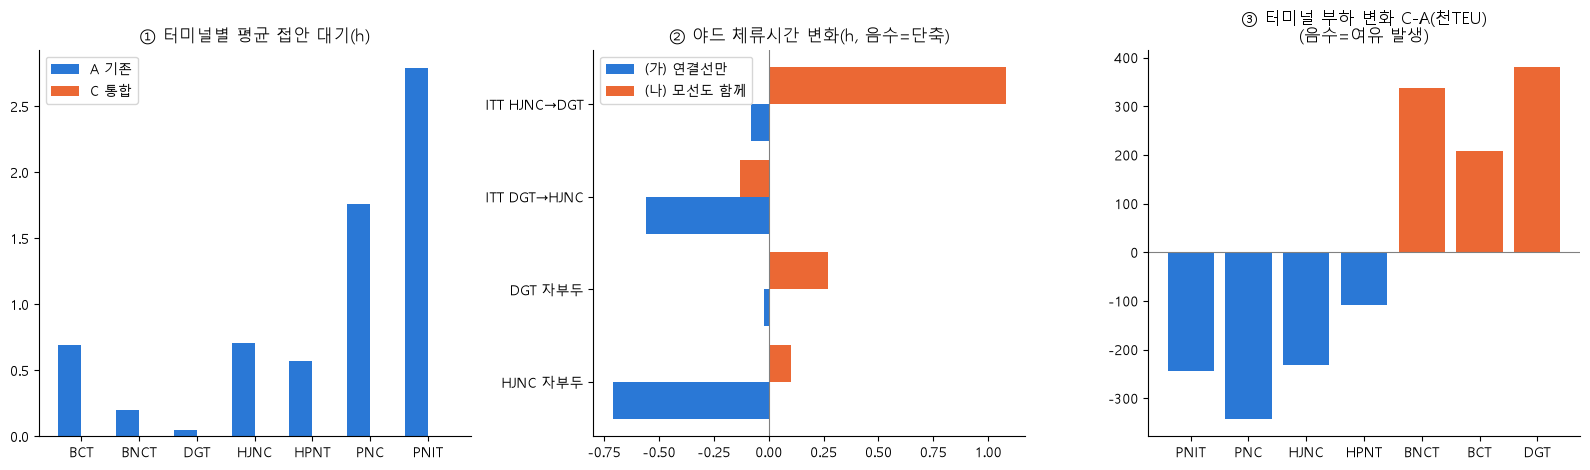

In [32]:
#셀 30: 요약 그림 (3칸)
import matplotlib.pyplot as plt                       # 그래프 라이브러리
plt.rcParams["font.family"] = "Malgun Gothic"         # 한글 글꼴 (윈도우 기본). 맥이면 "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False            # 마이너스 기호 깨짐 방지
BLUE, ORANGE = "#2a78d6", "#eb6834"                   # 기존/통합 색

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

# ① 터미널별 평균 대기시간: A vs C (셀 16의 cmp_term)
x = np.arange(len(cmp_term))                          # 터미널 위치
ax[0].bar(x - 0.2, cmp_term["A 평균대기h"], 0.4, color=BLUE, label="A 기존")
ax[0].bar(x + 0.2, cmp_term["C 평균대기h"], 0.4, color=ORANGE, label="C 통합")
ax[0].set_xticks(x); ax[0].set_xticklabels(cmp_term.index)
ax[0].set_title("① 터미널별 평균 접안 대기(h)"); ax[0].legend()

# ② 환적 유형별 체류시간 변화: (가) vs (나)
y = np.arange(len(summary_dwell))
ax[1].barh(y - 0.2, summary_dwell["(가) 연결선만 이동 변화(h)"], 0.4, color=BLUE, label="(가) 연결선만")
ax[1].barh(y + 0.2, summary_dwell["(나) 모선도 이동 변화(h)"], 0.4, color=ORANGE, label="(나) 모선도 함께")
ax[1].set_yticks(y); ax[1].set_yticklabels(summary_dwell.index)
ax[1].axvline(0, color="gray", lw=0.8)                # 0 기준선
ax[1].set_title("② 야드 체류시간 변화(h, 음수=단축)"); ax[1].legend()

# ③ 터미널 부하 변화 (셀 28의 보정 결과)
lt = out[1]
ax[2].bar(lt.index, lt["변화(천TEU)"], color=[BLUE if v < 0 else ORANGE for v in lt["변화(천TEU)"]])
ax[2].axhline(0, color="gray", lw=0.8)
ax[2].set_title("③ 터미널 부하 변화 C-A(천TEU)\n(음수=여유 발생)")

for a in ax:                                          # 위·오른쪽 테두리 제거로 깔끔하게
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "sim_summary.png", dpi=200)     # 그림 저장
plt.show()

# 분석 요약

## 1. 가설
통합 운영으로 선박(연결선)의 접안 대기가 줄면 환적 컨테이너의 야드 체류시간이 줄어든다.

## 2. 결과
1. **접안 대기는 줄지만 원래 작다.** 통합(C)에서 접안 대기가 사실상 사라지지만(10회 기준 평균 0.87h → 0.00h), A의 대기 자체가 1h 미만이고 대부분의 선박(약 85%)은 변화가 없다. 효과는 혼잡한 터미널(PNIT, PNC, BCT)의 일부 호출에 집중된다.
2. **야드 체류시간은 거의 변하지 않는다.** 체류시간은 180~280h(약 7~12일)인데 변화는 모든 환적 유형에서 ±1h 안팎(±0.6% 이내)이다. **가설은 이 데이터·설정에서 확인되지 않았다.**
3. **효과의 방향은 어느 쪽이 막혀 있었는지에 달려 있다.** 모선이 앞당겨지면 반입이 빨라져 체류시간이 늘고, 연결선이 앞당겨지면 반출이 빨라져 줄어든다.
   - 두 배가 같은 폭으로 앞당겨지면 상쇄된다 (HJNC 자부두: 모선 -0.82h, 연결선 -0.73h).
   - 연결선이 이미 대기 없이 들어오던 터미널(DGT)에 있으면 모선만 앞당겨져 체류시간이 오히려 늘 수 있다 (ITT HJNC→DGT: 모선 -1.19h, 연결선 -0.08h, 체류 +1.11h).
4. **통합의 실질 효과는 부하 재분배다.** 혼잡 터미널(PNC, PNIT, HJNC, HPNT)의 부하가 줄고 한가한 터미널(DGT, BNCT, BCT)로 옮겨 간다. 줄어든 부하는 그 터미널이 더 받을 수 있는 여유 물량으로 해석할 수 있다. 전체 합계는 같아서 물량은 이동만 한다.

## 3. 해석과 시사점
- 체류시간을 줄이려면 통합 운영만으로는 부족하고, **연결선을 모선보다 더 앞당기는 별도 조치**(예: 연결선 우선 접안)가 필요하다.
- 통합 운영은 접안 혼잡이 큰 터미널의 부담을 덜어 주는 용도로 의미가 있다. 다만 DGT 부하가 연간 현실 처리량(약 110만 TEU)을 넘는 수준으로 늘어나므로, 한가한 터미널의 수용 능력은 별도로 확인해야 한다.

## 4. 한계 (이 결과를 확정 수치로 쓰면 안 되는 이유)
1. **도착 시각이 없다.** 도착 시각을 계획 접안(ETB)으로 두어서 실제 박지 대기(중앙값 약 30h)가 빠져 있다. 반영하면 앞당겨지는 폭이 크게 달라질 수 있다.
2. **안벽 모델이 단순하다.** 크레인, 흘수, 선석 경계, 야드 장치능력, 터미널 전환 비용을 반영하지 않았다.
3. **설정에 민감하다.** 길이 여유 10%·교체 2h(규칙 기준)로 돌리면 A가 과도하게 막혀 통합 효과가 부풀려진다. 현재 설정은 관측 대기와 가장 가깝지만 최적이라는 보장은 없다.
4. **데이터가 비어 있다.** DGT 물량 69% 결측, DGT 길이 매칭 89.8%, DGT 자부두 환적은 154건뿐이고, 야드 체류시간은 HJNC·DGT에서만 계산할 수 있다. 컨테이너선이 아닌 선박(준설선 등)도 일부 포함되어 있다.
5. **연동 가정.** 반입이 모선 접안과, 반출이 연결선 접안과 같은 폭으로 움직인다고 가정했다. 통합으로 모선·연결선이 같은 터미널에 접안하면 타부두 환적이 자부두 환적으로 바뀔 수 있는데 이 효과는 넣지 않았다.
6. **반복 횟수의 의미.** 100회·500회로 늘려도 줄어드는 것은 길이를 무작위로 채우는 불확실성뿐이다. 위 1~5의 한계는 그대로다.

## 5. 다음 단계
1. 포트미스 박지 대기를 도착 시각에 반영해 재실행한다.
2. 연결선을 10~50h 앞당기는 시나리오와 연결선 우선 접안 시나리오를 추가한다.
3. 설정(길이 여유, 교체 간격)별 민감도 표를 만든다.
4. DGT 물량 결측을 보완하고 터미널별 처리능력 대비 이용률을 계산한다.

# 시뮬레이션 결과 요약

## 0. 실행 조건
- **입력**: 2025년 신항 7개 터미널 접안 7,041건 (선석배정현황 + 선박 제원 길이)
- **시나리오**: A = 터미널별 기존 운영, C = 7개 터미널 선석 통합(어느 안벽이든 사용)
- **규칙**: 안벽을 연속 직선(m)으로 보고 선박 길이만큼 점유, 도착 순서대로 가장 빠른 자리에 배정, 원래 터미널 우선, 한 번 배정하면 변경 없음
- **설정**: 선박 길이 여유 0%, 교체 간격 0h, 도착 시각 = 계획 접안(ETB)
- **반복**: 길이를 모르는 선박의 길이를 무작위로 채워 **500회** 실행하고, 앞 10회·100회·500회로 각각 요약했다. 이하 분석 수치는 **100회 기준**이다.

## 1. 반복 횟수별 비교 (수렴 확인)

| 반복 횟수 | A 평균 대기(h) | A 95% 구간 | C 평균 대기(h) | C 이동 비율(%) | DGT 부하 변화(천TEU) | HJNC 부하 변화(천TEU) |
|---|---|---|---|---|---|---|
| 10 | 0.867 | ±0.051 | 0.001 | 11.19 | +393.5 | -231.3 |
| 100 | 0.931 | ±0.016 | 0.002 | 11.07 | +380.1 | -231.2 |
| 500 | 0.943 | ±0.007 | 0.002 | 11.07 | +380.5 | -231.7 |

- 10회는 A 평균 대기가 100·500회보다 낮게(0.87h) 나와 오차가 크다. 100회와 500회는 거의 같아서(0.93h vs 0.94h), 100회면 충분히 수렴한다.

## 2. 접안 대기시간 (100회 기준)

| 지표 | A 기존 | C 통합 |
|---|---|---|
| 평균 대기 | 0.93h | 0.00h |
| 대기가 생긴 호출(0.5h 초과) | 10.6% | 0.1% |
| 다른 터미널로 이동한 호출 | 0% | 11.1% |

| 터미널 | A 평균대기(h) | C 평균대기(h) | 변화(h) |
|---|---|---|---|
| PNIT | 2.79 | 0.00 | -2.79 |
| PNC | 1.76 | 0.00 | -1.76 |
| HJNC | 0.71 | 0.00 | -0.71 |
| BCT | 0.69 | 0.00 | -0.69 |
| HPNT | 0.57 | 0.00 | -0.57 |
| BNCT | 0.20 | 0.00 | -0.20 |
| DGT | 0.05 | 0.00 | -0.05 |

- 접안이 0.5h 넘게 앞당겨진 선박: 7,041척 중 1,108척(15.7%), 최대 약 42h (BCT의 MSC C. MONTAINE)
- 선박별 대기 변화(C−A): 평균 -0.93h, 중앙값 0h

## 3. 환적 컨테이너 야드 체류시간 (100회 기준)

(가) 연결선만 앞당겨짐 / (나) 모선·연결선 모두 앞당겨짐 (변화, 시간, 음수 = 단축)

| 구분 | 컨테이너 | 기존 평균(h) | (가) 변화 | (나) 변화 | 연결선 접안 변화(평균) | 모선 접안 변화(평균) |
|---|---|---|---|---|---|---|
| HJNC 자부두 환적 | 1,487 | 196.2 | -0.71 | +0.10 | -0.73h | -0.81h |
| DGT 자부두 환적 | 154 | 281.0 | -0.02 | +0.27 | -0.04h | -0.29h |
| ITT DGT→HJNC | 18,120 | 283.6 | -0.56 | -0.13 | -0.56h | -0.43h |
| ITT HJNC→DGT | 20,126 | 178.3 | -0.08 | +1.08 | -0.08h | -1.16h |

- 연결선 접안이 가장 크게 앞당겨진 건: HJNC 자부두 -24.8h, ITT DGT→HJNC -17.0h, DGT 자부두와 ITT HJNC→DGT는 -4.0h
- ITT 기존 체류시간의 중앙값: DGT→HJNC 185.4h, HJNC→DGT 143.9h (평균이 중앙값보다 큰 것은 일부 장기 체류 컨테이너 때문)
- 매칭률: HJNC 자부두 모선 99.8%·연결선 100%, DGT 자부두 76.8%·76.4%, ITT 모선 99.9%·연결선 100%

## 4. 터미널 부하 변화 (연간, 천TEU, 결측 보정, 100회 기준)

| 터미널 | A | C | 변화 | 변화(%) |
|---|---|---|---|---|
| PNC | 5,054.0 | 4,711.7 | -342.3 | -6.8 |
| PNIT | 2,969.9 | 2,726.7 | -243.2 | -8.2 |
| HJNC | 2,782.1 | 2,550.9 | -231.2 | -8.3 |
| HPNT | 2,492.8 | 2,384.2 | -108.6 | -4.4 |
| BCT | 1,768.5 | 1,975.9 | +207.4 | +11.7 |
| BNCT | 2,456.5 | 2,794.1 | +337.6 | +13.7 |
| DGT | 873.2 | 1,253.3 | +380.1 | +43.5 |
| 합계 | 18,397 | 18,397 | 0 | 0 |

- DGT는 물량의 69%가 비어 있어 같은 터미널 중앙값으로 보정했다. 관측 물량만 쓴 경우 DGT는 313.3 → 752.8천TEU(+439.5, +140%)이며, 결측 때문에 A가 과소 계산된 값이다.